In [1]:
%pip install numpy pandas matplotlib 

Defaulting to user installation because normal site-packages is not writeable
Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.1.2 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


✅ Fichier 'charges_non_flexibles2.csv' exporté avec succès.
✅ Fichier 'bornes_recharge_ve4.csv' exporté avec succès.


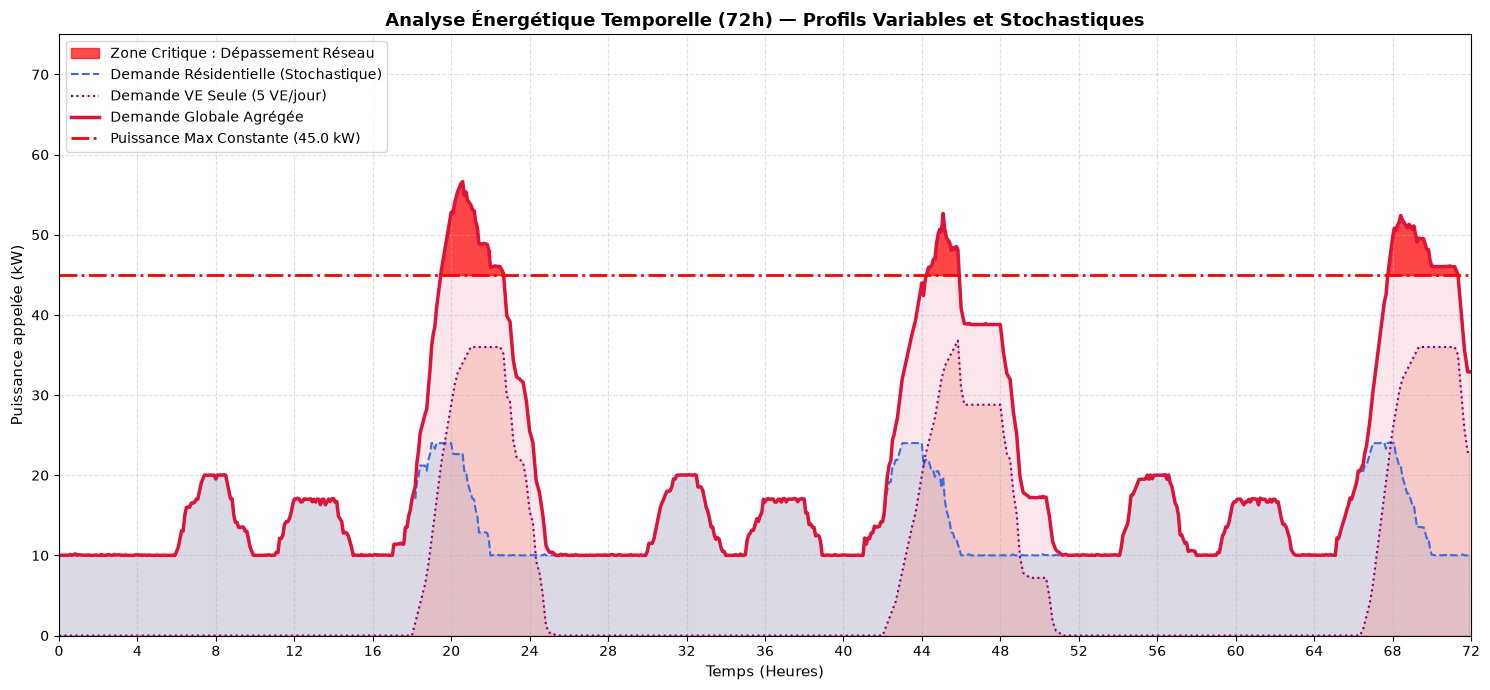

--- RÉSULTATS COMBINÉS (72H) ---
Puissance maximale globale atteinte au pic : 56.63 kW
Heure exacte du pic de demande globale : 20h34
Marge restante au pic : -11.63 kW

--- ANALYSE CRITIQUE DU RÉSEAU ---
Durée cumulée de dépassement de la limite : 510.0 minutes (8.50 heures)


In [2]:
# %% FUSION ET EXTENSION SUR 72H AVEC VARIATIONS JOURNALIÈRES INDÉPENDANTES
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# =====================================================================
# CONFIGURATION DES CONSTANTES ET LIMITES
# =====================================================================
LIMITE_PUISSANCE_KW = 45.0  # Valeur de puissance constante maximale
total_heures = 72
nb_jours = total_heures // 24

# =====================================================================
# 1. GENERATION DU PROFIL DE CHARGE STOCHASTIQUE D'HIVER (72H INDÉPENDANT)
# =====================================================================
nb_total_appartements = 20
dt_simulation_sec = 300  # Pas de temps cible (300s = 5 min)
N_minutes = total_heures * 60

charge_totale_batiment_W = np.zeros(N_minutes)
np.random.seed(40)

# Boucle par jour pour garantir des variations stochastiques quotidiennes différentes
for jour in range(nb_jours):
    idx_debut_jour = jour * 1440
    idx_fin_jour = (jour + 1) * 1440
    minute_de_la_journee = np.arange(1440)
    
    for apt in range(nb_total_appartements):
        # A. Bruit de fond / Talon permanent (propre à chaque jour)
        talon_base = 400.0 + np.random.normal(0, 60, 1440)
        charge_totale_batiment_W[idx_debut_jour:idx_fin_jour] += np.clip(talon_base, 500, 1500)
        
        # B. Première pointe (Matin) : 06h00 à 10h00
        shift_matin = np.random.randint(-60.0, 30.0)
        plage_matin = (minute_de_la_journee >= 420 + shift_matin) & (minute_de_la_journee <= 570 + shift_matin)
        activation_matin = np.random.rand(1440) < 0.995
        charge_totale_batiment_W[idx_debut_jour:idx_fin_jour][plage_matin & activation_matin] += 500.0
        
        # C. Deuxième pointe (Midi) : 11h30 à 13h30
        shift_midi = np.random.randint(-30, 30)
        plage_midi = (minute_de_la_journee >= 690 + shift_midi) & (minute_de_la_journee <= 870 + shift_midi)
        activation_midi = np.random.rand(1440) < 0.98
        charge_totale_batiment_W[idx_debut_jour:idx_fin_jour][plage_midi & activation_midi] += 350.0
        
        # D. Troisième pointe (Soir) : 17h00 à 21h00
        shift_soir = np.random.randint(-60, 60)
        plage_soir = (minute_de_la_journee >= 1080 + shift_soir) & (minute_de_la_journee <= 1260 + shift_soir)
        activation_soir = np.random.rand(1440) < 0.995
        charge_totale_batiment_W[idx_debut_jour:idx_fin_jour][plage_soir & activation_soir] += 700.0

# Interpolation vers le pas cible (5 min)
temps_base_sec = np.arange(0, len(charge_totale_batiment_W)) * 60
temps_cible_sec = np.arange(0, total_heures * 3600, dt_simulation_sec)
charge_interpolee_W = np.interp(temps_cible_sec, temps_base_sec, charge_totale_batiment_W)

P_base_totale_kW = charge_interpolee_W / 1000.0
temps_communs_heures = temps_cible_sec / 3600.0

# Exportation 1 : Demande résidentielle seule
df_export_res = pd.DataFrame({'Temps_heures': temps_communs_heures, 'P_base_kW': P_base_totale_kW})
# df_export_res.to_csv('charges_non_flexibles2.csv', sep=';', index=False)
print("✅ Fichier 'charges_non_flexibles2.csv' exporté avec succès.")

# =====================================================================
# 2. GENERATION DU PROFIL DE RECHARGE DES VÉHICULES ÉLECTRIQUES (72H)
# =====================================================================
N_VEHICULES = 5
PAS_TEMPS_VE = 10/60
TEMPS_VE = np.arange(0, total_heures, PAS_TEMPS_VE)  # Changement icı : Étallé sur 72h

Heure_Arrivee_Moyenne = 19.0
Heure_Arrivee_Std = 1.0
Energie_Moyenne_kWh = 33.0
Energie_Std_kWh = 2.0
PROBA_7_2kW = 0.95
PUISSANCES_DISPO = [7.2, 9.6]
PROBAS_PUISSANCE = [PROBA_7_2kW, 1.0 - PROBA_7_2kW]
T_RAMP = 90/60
SOC_TAPER = 0.95

def generer_profil_individuel(t_start, e_req, p_max, temps):
    profil = np.zeros_like(temps)
    if e_req <= 0: return profil
    e_accumulee = 0.0
    en_charge = False
    t_relative = 0.0
    for idx, t in enumerate(temps):
        if t >= t_start and not en_charge and e_accumulee < e_req:
            en_charge = True
        if en_charge:
            if t_relative < T_RAMP:
                p_actuelle = p_max * (t_relative / T_RAMP)
            elif e_accumulee >= (SOC_TAPER * e_req):
                fraction_restante = (e_req - e_accumulee) / (e_req * (1 - SOC_TAPER))
                p_actuelle = p_max * max(0.05, fraction_restante)
            else:
                p_actuelle = p_max
            e_accumulee += p_actuelle * PAS_TEMPS_VE
            profil[idx] = p_actuelle
            t_relative += PAS_TEMPS_VE
            if e_accumulee >= e_req:
                en_charge = False
    return profil

# Calcul stochastique VE autonome avec variations quotidiennes
P_total_VE_natif = np.zeros_like(TEMPS_VE)

for jour in range(nb_jours):
    offset_heures = jour * 24
    for i in range(N_VEHICULES):
        # Génération de paramètres uniques pour CHAQUE véhicule et CHAQUE jour
        t_start = np.random.normal(Heure_Arrivee_Moyenne, Heure_Arrivee_Std) + offset_heures
        e_req = max(1.0, np.random.normal(Energie_Moyenne_kWh, Energie_Std_kWh))
        p_max = np.random.choice(PUISSANCES_DISPO, p=PROBAS_PUISSANCE)
        
        P_total_VE_natif += generer_profil_individuel(t_start, e_req, p_max, TEMPS_VE)

# Exportation 2 : Profil VE seul
df_export_ve = pd.DataFrame({'Temps_Heures': np.round(TEMPS_VE, 4), 'P_VE_kW': np.round(P_total_VE_natif, 2)})
# df_export_ve.to_csv('bornes_recharge_ve4.csv', sep=';', index=False)
print("✅ Fichier 'bornes_recharge_ve4.csv' exporté avec succès.")

# =====================================================================
# 3. INTERPOLATION DU PROFIL VE ET CALCUL AGRÉGÉ
# =====================================================================
P_VE_interpole_kW = np.interp(temps_communs_heures, TEMPS_VE, P_total_VE_natif)
P_somme_totale_kW = P_base_totale_kW + P_VE_interpole_kW

# =====================================================================
# 4. CALCUL DE LA DURÉE DE DÉPASSEMENT
# =====================================================================
indices_depassement = P_somme_totale_kW > LIMITE_PUISSANCE_KW
nb_pas_depassement = np.sum(indices_depassement)
duree_depassement_min = nb_pas_depassement * (dt_simulation_sec / 60.0)
duree_depassement_heures = duree_depassement_min / 60.0

# =====================================================================
# 5. GRAPHIQUE CORRIGÉ (72 HEURES)
# =====================================================================
plt.figure(figsize=(15, 7), dpi=100)
plt.fill_between(temps_communs_heures, 0, P_base_totale_kW, color='skyblue', alpha=0.3)
plt.fill_between(temps_communs_heures, 0, P_VE_interpole_kW, color='salmon', alpha=0.25)
plt.fill_between(temps_communs_heures, 0, P_somme_totale_kW, color='crimson', alpha=0.1)

plt.fill_between(temps_communs_heures, LIMITE_PUISSANCE_KW, P_somme_totale_kW, 
                 where=(P_somme_totale_kW > LIMITE_PUISSANCE_KW),
                 color='red', alpha=0.7, step="mid", label="Zone Critique : Dépassement Réseau")

plt.plot(temps_communs_heures, P_base_totale_kW, color='royalblue', linewidth=1.5, linestyle='--', label="Demande Résidentielle (Stochastique)")
plt.plot(temps_communs_heures, P_VE_interpole_kW, color='purple', linewidth=1.5, linestyle=':', label=f"Demande VE Seule ({N_VEHICULES} VE/jour)")
plt.plot(temps_communs_heures, P_somme_totale_kW, color='crimson', linewidth=2.5, label="Demande Globale Agrégée")
plt.axhline(y=LIMITE_PUISSANCE_KW, color='red', linestyle='-.', linewidth=2, label=f"Puissance Max Constante ({LIMITE_PUISSANCE_KW} kW)")

plt.title("Analyse Énergétique Temporelle (72h) — Profils Variables et Stochastiques", fontsize=13, fontweight='bold')
plt.xlabel("Temps (Heures)", fontsize=11)
plt.ylabel("Puissance appelée (kW)", fontsize=11)
plt.xlim(0, total_heures)
plt.xticks(np.arange(0, total_heures + 1, 4))  # Graduation toutes les 4 heures pour plus de clarté
plt.ylim(bottom=0, top=max(75, np.max(P_somme_totale_kW) + 10)) 
plt.grid(True, linestyle='--', alpha=0.4)
plt.legend(loc="upper left", fontsize=10)
plt.tight_layout()
plt.show()

# =====================================================================
# 6. AFFICHAGE DES MÉTRIQUES CLÉS
# =====================================================================
pic_total = np.max(P_somme_totale_kW)
heure_pic_total = temps_communs_heures[np.argmax(P_somme_totale_kW)]
print(f"--- RÉSULTATS COMBINÉS (72H) ---")
print(f"Puissance maximale globale atteinte au pic : {pic_total:.2f} kW")
print(f"Heure exacte du pic de demande globale : {int(heure_pic_total)}h{int((heure_pic_total%1)*60):02d}")
print(f"Marge restante au pic : {LIMITE_PUISSANCE_KW - pic_total:.2f} kW")
print(f"\n--- ANALYSE CRITIQUE DU RÉSEAU ---")
print(f"Durée cumulée de dépassement de la limite : {duree_depassement_min:.1f} minutes ({duree_depassement_heures:.2f} heures)")
